In [2]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

RESULTS_DIR = Path("../outputs/results")
LOG_DIR = Path("../outputs/logs")
FIG_DIR = Path("../outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 1. Display Final D2t Test Set Performance Table for SMGN
smgn_csv = RESULTS_DIR / "final_test_metrics_smgn.csv"
df_smgn = pd.read_csv(smgn_csv)
print("=== SMGN Final D2t Test Set Performance ===")
display(df_smgn.sort_values(by="Test Rank-1", ascending=False))

# 2. Load Joblib Training & Validation Histories
backbones = {
    "convnext_tiny": "ConvNeXt-Tiny",
    "efficientnet_v2_s": "EfficientNetV2-S",
    "mobilenetv4": "MobileNetV4",
}

histories = {}
for key, label in backbones.items():
    hist_file = LOG_DIR / f"smgn_{key}_history.joblib"
    if hist_file.exists():
        histories[key] = (label, joblib.load(hist_file))
    else:
        print(f"Warning: {hist_file} not found.")

=== SMGN Final D2t Test Set Performance ===


,Architecture,Backbone,Best Epoch,Test mAP,Test Rank-1,Test Rank-5,Test Rank-10
2,SMGN,convnext_tiny,28,0.8205,0.8477,0.9630,0.9753
0,SMGN,mobilenetv4,48,0.7052,0.7037,0.9424,0.9918
1,SMGN,efficientnet_v2_s,48,0.6713,0.6914,0.9218,0.9588


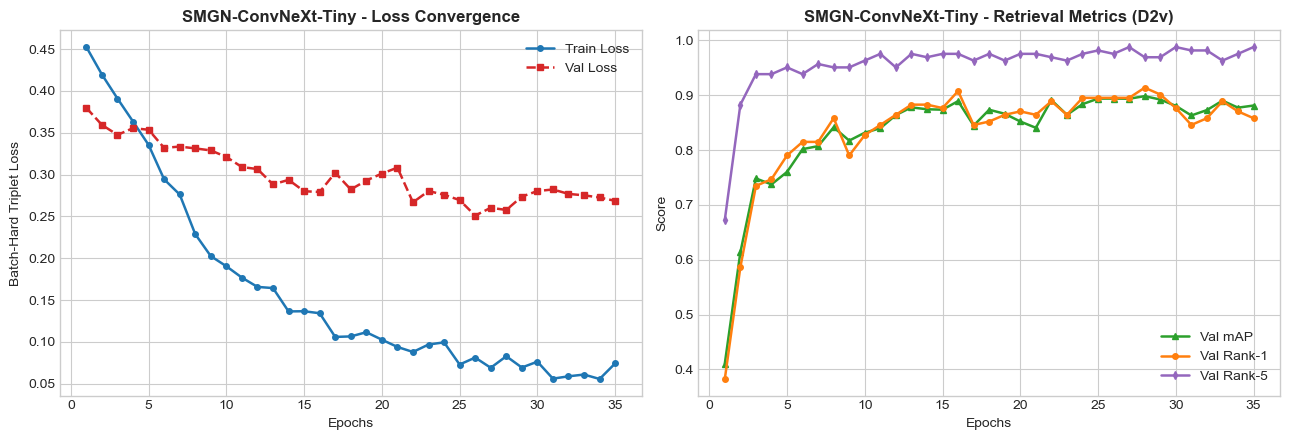

Saved ..\outputs\figures\smgn_convnext_tiny_curves.png


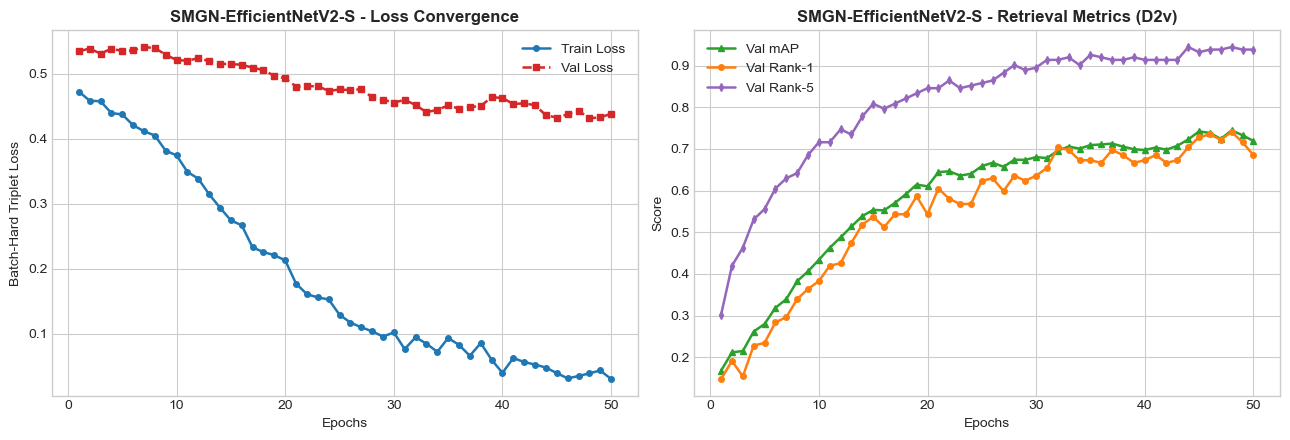

Saved ..\outputs\figures\smgn_efficientnet_v2_s_curves.png


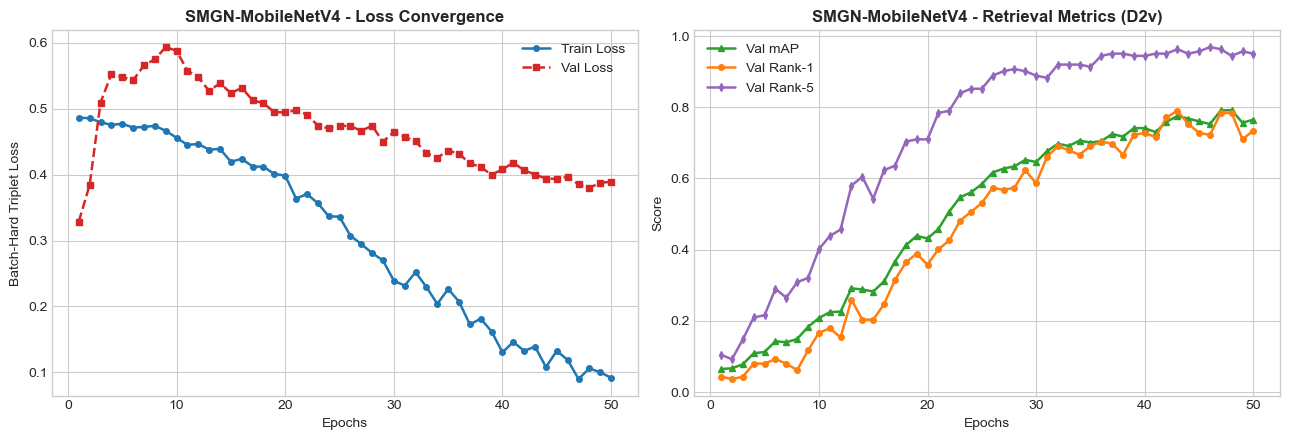

Saved ..\outputs\figures\smgn_mobilenetv4_curves.png


In [3]:
for key, (label, hist) in histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    epochs = hist["epoch"]

    # Left Panel: Batch-Hard Triplet Loss Convergence (Train + Val)
    axes[0].plot(
        epochs, hist["train_loss"],
        marker="o", markersize=4, linewidth=1.8, color="#1f77b4", label="Train Loss"
    )
    if "val_loss" in hist:
        axes[0].plot(
            epochs, hist["val_loss"],
            marker="s", markersize=4, linestyle="--", linewidth=1.8, color="#d62728", label="Val Loss"
        )
    axes[0].set_title(f"SMGN-{label} - Loss Convergence", fontweight="bold")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Batch-Hard Triplet Loss")
    axes[0].legend()

    # Right Panel: Validation Retrieval Metrics (D2v)
    axes[1].plot(
        epochs, hist["val_mAP"],
        marker="^", markersize=4, linewidth=1.8, color="#2ca02c", label="Val mAP"
    )
    axes[1].plot(
        epochs, hist["val_rank1"],
        marker="o", markersize=4, linewidth=1.8, color="#ff7f0e", label="Val Rank-1"
    )
    axes[1].plot(
        epochs, hist["val_rank5"],
        marker="d", markersize=4, linewidth=1.8, color="#9467bd", label="Val Rank-5"
    )
    axes[1].set_title(f"SMGN-{label} - Retrieval Metrics (D2v)", fontweight="bold")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Score")
    axes[1].legend()

    plt.tight_layout()
    out_fig = FIG_DIR / f"smgn_{key}_curves.png"
    plt.savefig(out_fig, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved {out_fig}")

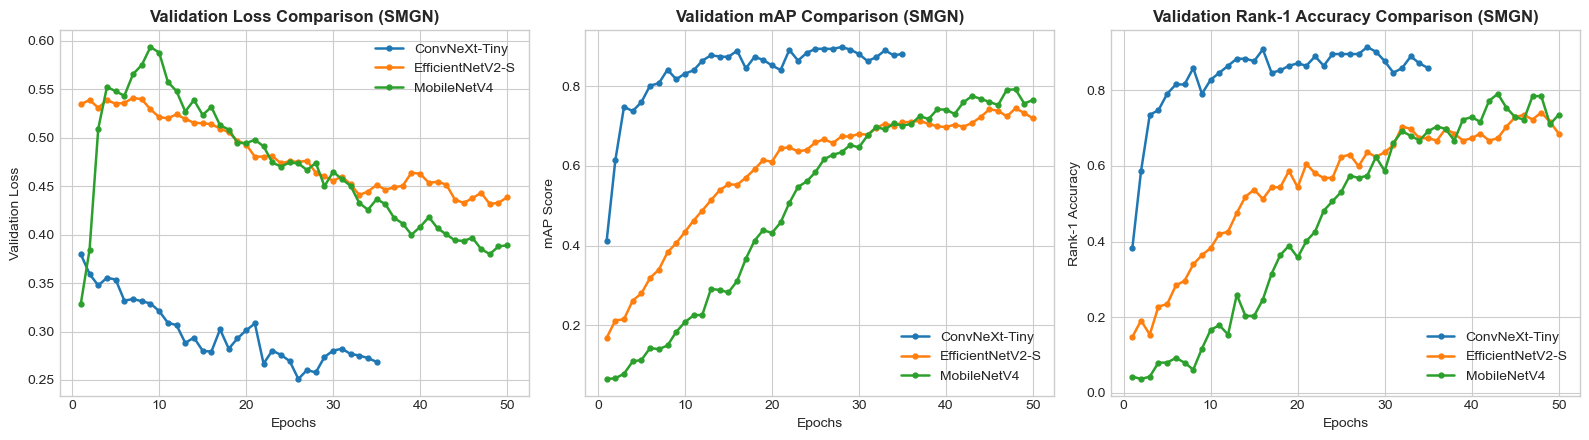

Saved ..\outputs\figures\smgn_backbone_comparison.png


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
metrics_to_plot = [
    ("val_loss", "Validation Loss Comparison (SMGN)", "Validation Loss"),
    ("val_mAP", "Validation mAP Comparison (SMGN)", "mAP Score"),
    ("val_rank1", "Validation Rank-1 Accuracy Comparison (SMGN)", "Rank-1 Accuracy"),
]

for ax, (metric_key, title, ylabel) in zip(axes, metrics_to_plot):
    for key, (label, hist) in histories.items():
        if metric_key in hist:
            ax.plot(hist["epoch"], hist[metric_key], marker="o", markersize=3.5, linewidth=1.8, label=label)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Epochs")
    ax.set_ylabel(ylabel)
    ax.legend()

plt.tight_layout()
comp_fig = FIG_DIR / "smgn_backbone_comparison.png"
plt.savefig(comp_fig, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved {comp_fig}")

In [5]:
pcb_csv = RESULTS_DIR / "final_test_metrics_pcb.csv"
if pcb_csv.exists():
    df_pcb = pd.read_csv(pcb_csv)
    df_combined = pd.concat([df_pcb, df_smgn], ignore_index=True)
    print("=== Combined PCB vs. SMGN Test Set Benchmark (D2t) ===")
    display(df_combined.sort_values(by=["Backbone", "Architecture"]))

=== Combined PCB vs. SMGN Test Set Benchmark (D2t) ===


,Architecture,Backbone,Best Epoch,Test mAP,Test Rank-1,Test Rank-5,Test Rank-10
0,PCB,convnext_tiny,15,0.8033,0.8354,0.9671,0.9835
5,SMGN,convnext_tiny,28,0.8205,0.8477,0.9630,0.9753
1,PCB,efficientnet_v2_s,33,0.6635,0.6955,0.9136,0.9465
4,SMGN,efficientnet_v2_s,48,0.6713,0.6914,0.9218,0.9588
2,PCB,mobilenetv4,49,0.6649,0.6461,0.8971,0.9753
3,SMGN,mobilenetv4,48,0.7052,0.7037,0.9424,0.9918
